<>:38: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:39: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:38: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:39: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
/var/folders/vj/p_wfrn2s5dd6k2_7ngzxs6j40000gn/T/ipykernel_99638/383805757.py:38: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  plt.ylabel('$C_v / T$  (cal $\cdot$ mol$^{-1} \cdot$ K$^{-2}$)')
/var/folders/vj/p_wfrn2s5dd6k2_7ngzxs6j40000gn/T/ipykernel_99638/383805757.py:39: Syntax

Resultados del Ajuste Lineal:
γ_exp (Intersección) = 1.6072e-04 cal / (mol·K^2)
α (Pendiente) = 1.1531e-05 cal / (mol·K^4)

Energía de Fermi calculada a partir del γ experimental: 5.2572 eV


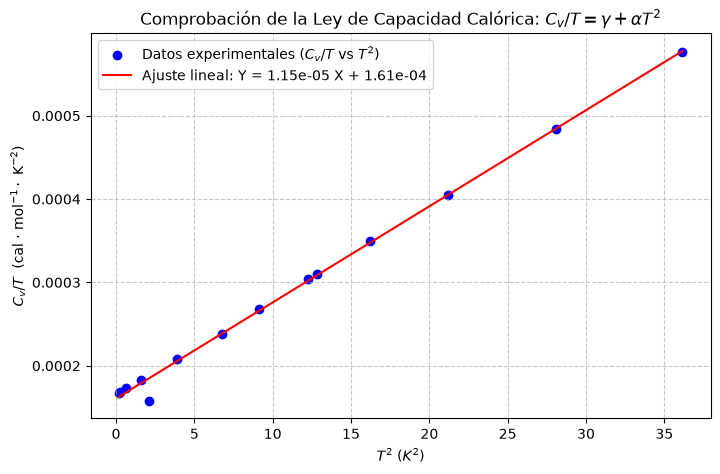

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Ingreso de los datos de la tabla (image.png)
# Temperaturas en K
T = np.array([0.418, 0.517, 0.787, 1.252, 1.452, 1.968, 2.603, 
              3.02, 3.498, 3.579, 4.023, 4.606, 5.301, 6.013])

# Capacidad calórica Cv, recordando aplicar el factor 10^-2 (cal / mol*K)
Cv = np.array([0.007, 0.0087, 0.0136, 0.0229, 0.0229, 0.041, 0.0621, 
               0.0809, 0.1065, 0.1109, 0.1407, 0.1867, 0.2567, 0.3464]) * 1e-2

# 2. Transformación de variables para la regresión
X = T**2
Y = Cv / T

# 3. Regresión lineal (polinomio de grado 1: Y = alpha * X + gamma)
# np.polyfit devuelve primero la pendiente (alpha) y luego el intercepto (gamma)
alpha, gamma = np.polyfit(X, Y, 1)

print(f"Resultados del Ajuste Lineal:")
print(f"γ_exp (Intersección) = {gamma:.4e} cal / (mol·K^2)")
print(f"α (Pendiente) = {alpha:.4e} cal / (mol·K^4)\n")

# 4. Cálculo de la Energía de Fermi (Ef) usando el gamma experimental
R = 1.987        # Constante de los gases en cal/(mol·K)
k_B = 8.617e-5   # Constante de Boltzmann en eV/K

# Despejando Ef de la fórmula teórica: gamma = (pi^2 / 2) * (R * k_B) / Ef
Ef = (np.pi**2 * R * k_B) / (2 * gamma)
print(f"Energía de Fermi calculada a partir del γ experimental: {Ef:.4f} eV")

# 5. Gráfica de los datos y el ajuste lineal
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='blue', label='Datos experimentales ($C_v/T$ vs $T^2$)')
plt.plot(X, alpha * X + gamma, color='red', label=f'Ajuste lineal: Y = {alpha:.2e} X + {gamma:.2e}')
plt.xlabel('$T^2$ ($K^2$)')
plt.ylabel('$C_v / T$  (cal $\cdot$ mol$^{-1} \cdot$ K$^{-2}$)')
plt.title('Comprobación de la Ley de Capacidad Calórica: $C_v/T = \gamma + \\alpha T^2$')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()